IMPORT RELEVANT PACKAGES


In [1]:
import numpy as np
import pandas as pd
import pandapower as pp
import pandapower.control as control
import pandapower.networks as nw
import pandapower.timeseries as timeseries
from pandapower.timeseries.data_sources.frame_data import DFData
import pandapower.plotting as plt
import matplotlib.pyplot as mplt            

IMPORT THE IEEE 24 NETWORK


Το μοντέλο είναι το έτοιμο IEEE RTS 24 του pandapower, με προέλευση δεδομένων PYPOWER.
Δεν αλλάζουμε παραγωγή, φορτία ή ηλεκτρικά χαρακτηριστικά του έτοιμου μοντέλου.
Τεκμηρίωση: https://pandapower.readthedocs.io/en/stable/networks/power_system_test_cases.html#case-24-ieee-rts

In [2]:
net = nw.case24_ieee_rts()

PLOT THE GRAPH OF THE NETWORK

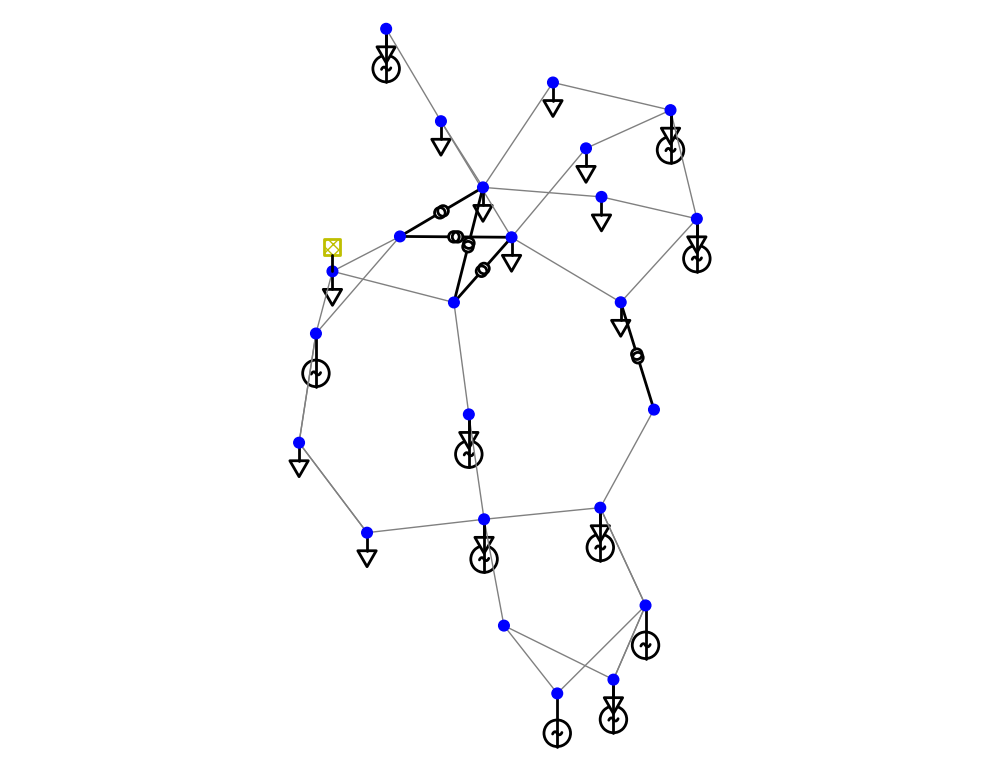

<Axes: >

In [3]:
plt.simple_plot(net,  plot_loads=True, plot_gens=True,load_size=2.0, gen_size=2.5,scale_size=True)       

DISPLAY THE SYMMARY OF THE NETWORK DATA

In [4]:
net


This pandapower network includes the following parameter tables:
   - bus (24 elements)
   - load (17 elements)
   - sgen (22 elements)
   - gen (10 elements)
   - shunt (1 element)
   - ext_grid (1 element)
   - line (33 elements)
   - trafo (5 elements)
   - poly_cost (33 elements)

DISPLAY THE BUS DATA

In [5]:
net.bus

,name,vn_kv,type,zone,in_service,max_vm_pu,min_vm_pu,geo
0,1,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [2.7759619498, -1.278020978], ..."
1,2,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [2.5012550969, -0.1447433104],..."
2,3,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [1.9820386365, -2.1490309973],..."
3,4,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [1.61982258, -0.5433284509], ""..."
4,5,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [1.7811971347, -1.049758788], ..."
5,6,138.0,b,2.0,True,1.05,0.95,"{""coordinates"": [1.2749925358, 0.1433862776], ..."
6,7,138.0,b,2.0,True,1.05,0.95,"{""coordinates"": [-0.4646735958, 0.7036672915],..."
7,8,138.0,b,2.0,True,1.05,0.95,"{""coordinates"": [0.1067929329, -0.2603906494],..."
8,9,138.0,b,1.0,True,1.05,0.95,"{""coordinates"": [0.8431378211, -1.4711207032],..."
9,10,138.0,b,2.0,True,1.05,0.95,"{""coordinates"": [0.5451378694, -0.950440448], ..."


DISPLAY THE LOAD DATA

In [6]:
net.load


,name,bus,p_mw,q_mvar,const_z_p_percent,const_z_q_percent,const_i_p_percent,const_i_q_percent,sn_mva,scaling,in_service,type,controllable
0,None,0,108.0,22.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
1,None,1,97.0,20.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
2,None,2,180.0,37.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
3,None,3,74.0,15.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
4,None,4,71.0,14.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
5,None,5,136.0,28.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
6,None,6,125.0,25.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
7,None,7,171.0,35.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
8,None,8,175.0,36.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False
9,None,9,195.0,40.0,0.0,0.0,0.0,0.0,NaN,1.0,True,None,False


DISPLAY THE GENARATOR DATA

In [7]:
net.gen


,name,bus,p_mw,vm_pu,sn_mva,min_q_mvar,max_q_mvar,scaling,slack,in_service,slack_weight,type,controllable,max_p_mw,min_p_mw,id_q_capability_characteristic,reactive_capability_curve,curve_style
0,None,0,10.0,1.035,NaN,0.0,10.0,1.0,False,True,0.0,None,True,20.0,16.0,<NA>,False,None
1,None,1,10.0,1.035,NaN,0.0,10.0,1.0,False,True,0.0,None,True,20.0,16.0,<NA>,False,None
2,None,6,80.0,1.025,NaN,0.0,60.0,1.0,False,True,0.0,None,True,100.0,25.0,<NA>,False,None
3,None,13,0.0,0.980,NaN,-50.0,200.0,1.0,False,True,0.0,None,True,0.0,0.0,<NA>,False,None
4,None,14,12.0,1.014,NaN,0.0,6.0,1.0,False,True,0.0,None,True,12.0,2.4,<NA>,False,None
5,None,15,155.0,1.017,NaN,-50.0,80.0,1.0,False,True,0.0,None,True,155.0,54.3,<NA>,False,None
6,None,17,400.0,1.050,NaN,-50.0,200.0,1.0,False,True,0.0,None,True,400.0,100.0,<NA>,False,None
7,None,20,400.0,1.050,NaN,-50.0,200.0,1.0,False,True,0.0,None,True,400.0,100.0,<NA>,False,None
8,None,21,50.0,1.050,NaN,-10.0,16.0,1.0,False,True,0.0,None,True,50.0,10.0,<NA>,False,None
9,None,22,155.0,1.050,NaN,-50.0,80.0,1.0,False,True,0.0,None,True,155.0,54.3,<NA>,False,None


DISPLAY THE EXTERNAL GRID DATA

In [8]:
net.ext_grid


,name,bus,vm_pu,va_degree,slack_weight,in_service,max_p_mw,min_p_mw,max_q_mvar,min_q_mvar
0,None,12,1.02,0.0,1.0,True,197.0,69.0,80.0,0.0


Run a load flow 

In [9]:
pp.runpp(net, algorithm="nr", init="flat", max_iteration=20, tolerance_mva=1e-8)

numba cannot be imported and numba functions are disabled.
Probably the execution is slow.
Please install numba to gain a massive speedup.
(or if you prefer slow execution, set the flag numba=False to avoid this warning!)


DISPLAY THE BUS RESULTS


In [10]:
net.res_bus #bus voltages

,vm_pu,va_degree,p_mw,q_mvar
0,1.035000,-8.043233,-64.000000,-32.119396
1,1.035000,-8.139101,-75.000000,-23.050478
2,0.951676,-5.803424,180.000000,37.000000
3,0.976219,-10.276936,74.000000,15.000000
4,1.006936,-10.523782,71.000000,14.000000
5,0.993775,-12.931678,136.000000,126.758954
6,1.025000,-8.188759,-115.000000,-49.350684
7,0.978985,-11.766839,171.000000,35.000000
8,0.962798,-7.676124,175.000000,36.000000
9,1.004967,-9.792732,195.000000,40.000000


DISPLAY THE LINE RESULTS


In [11]:
net.res_line

,p_from_mw,q_from_mvar,p_to_mw,q_to_mvar,pl_mw,ql_mvar,i_from_ka,i_to_ka,i_ka,vm_from_pu,va_from_degree,vm_to_pu,va_to_degree,loading_percent
0,12.460981,-27.017135,-12.457081,-22.356203,0.003899,-49.373338,0.120265,0.103451,0.120265,1.035000,-8.043233,1.035000,-8.139101,16.426412
1,-7.103645,39.962579,8.072948,-41.867159,0.969302,-1.904580,0.164070,0.187444,0.187444,1.035000,-8.043233,0.951676,-5.803424,25.601980
2,58.642665,19.173952,-57.858123,-18.520444,0.784542,0.653509,0.249396,0.252409,0.252409,1.035000,-8.043233,1.006936,-10.523782,34.475188
3,39.664544,36.467529,-38.733561,-36.342875,0.930983,0.124654,0.217799,0.227626,0.227626,1.035000,-8.139101,0.976219,-10.276936,31.090206
4,47.792538,8.939151,-46.669031,-9.951761,1.123507,-1.012610,0.196538,0.200889,0.200889,1.035000,-8.139101,0.993775,-12.931678,27.438392
5,21.524431,-15.512504,-21.299702,13.430182,0.224729,-2.082322,0.116638,0.109417,0.116638,0.951676,-5.803424,0.962798,-7.676124,15.930901
6,-35.266439,21.342875,35.760870,-22.071097,0.494431,-0.728222,0.176661,0.182607,0.182607,0.976219,-10.276936,0.962798,-7.676124,24.941286
7,-13.141877,4.520444,13.188103,-6.759958,0.046225,-2.239514,0.057743,0.061695,0.061695,1.006936,-10.523782,1.004967,-9.792732,8.426535
8,-89.330969,-116.807193,90.457131,-123.889769,1.126162,-240.696962,0.619070,0.638602,0.638602,0.993775,-12.931678,1.004967,-9.792732,87.223156
9,115.000000,49.350684,-112.616824,-41.815229,2.383176,7.535455,0.510786,0.513374,0.513374,1.025000,-8.188759,0.978985,-11.766839,70.118917


In [14]:
net.res_trafo

,p_hv_mw,q_hv_mvar,p_lv_mw,q_lv_mvar,pl_mw,ql_mvar,i_hv_ka,i_lv_ka,vm_hv_pu,va_hv_degree,vm_lv_pu,va_lv_degree,loading_percent
0,210.723559,20.701437,-209.597379,20.379663,1.126180,41.081100,0.539280,0.925764,0.985589,5.360848,0.951676,-5.803424,55.319731
1,105.928424,6.894883,-105.651214,3.217259,0.277210,10.112142,0.267556,0.459305,0.995926,-2.207779,0.962798,-7.676124,27.446098
2,120.407523,24.303477,-120.046872,-11.147527,0.360652,13.155949,0.305179,0.523890,1.010374,-1.569925,0.962798,-7.676124,31.305463
3,153.628983,-27.225789,-153.041696,48.648971,0.587286,21.423182,0.393253,0.668531,0.995926,-2.207779,1.004967,-9.792732,39.948550
4,169.439092,-9.453814,-168.764034,34.078764,0.675058,24.624951,0.421617,0.716749,1.010374,-1.569925,1.004967,-9.792732,42.829866


Calculating the total network losess

In [12]:
line_losses = net.res_line.pl_mw.sum()  # Line losses
trafo_losses = net.res_trafo.pl_mw.sum()  # Transformer losses
total_losses = line_losses + trafo_losses

Displaying the total power loses

In [13]:
print(' Total Active Power Losses = %4.4f MW'%total_losses)

 Total Active Power Losses = 52.7727 MW
